# 2nd round - Step 3: feature engineering and selection

1. **Join** each policy row with its customer, address and the weather of its address and year.
2. **Extract information**: season on cover, property age, age at first licence, sum insured per
   bedroom, the address's climate next to the year's weather, claims history known at the start
   of each year (policy, customer across lines, address), the other lines the customer holds.
3. **Targets**: each row's claims by peril (count and cost) and the share already reported.
4. **Selection**: every column must earn its place. Rules first (leakage, personal data,
   governance, constants, exact redundancy), then out-of-time tests against random *probe*
   columns, then near-duplicates. Every decision is in `reports/03_features/feature_register.csv`.

The script `python 03_feature_engineering.py` builds all three lines; this notebook rebuilds one
line (buildings) to show the steps, then reads the full run's register and outputs.

In [1]:
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config as C
import helpers as H

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"{C.ROUND} - {C.MARKET} - {C.COMPETITION}")

fe = importlib.import_module("03_feature_engineering")

2nd round - emerging market - IAA AI-Assisted Hackathon 2026 - Part 2


## 1. Reference tables, claims and reporting patterns

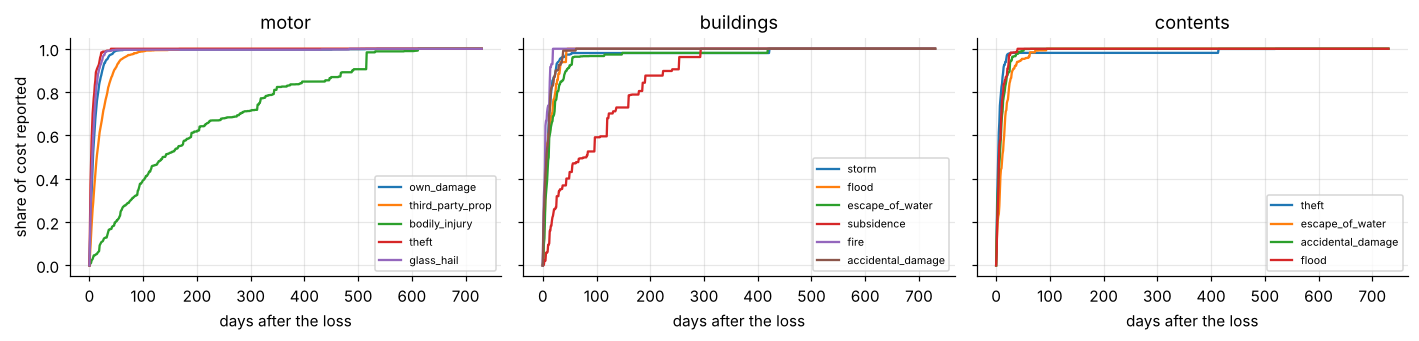

In [2]:
ref = {t: H.read_table(t, "clean") for t in ("customers", "addresses", "weather")}
claims = H.read_table("claims", "clean")
all_rows = pd.concat([H.read_table(f"{k}_{l}", "clean", columns=["row_id", "policy_id", "customer_id", "address_id",
                                                                  "period_start", "exposure"]).assign(line=l)
                      for l in C.LINES for k in ("policies", "test")], ignore_index=True)
ev = fe.claim_events(claims, all_rows)
nonrep = claims.loc[claims["status"] != "repudiated"]
cap = nonrep.groupby(["line", "peril"])["net_incurred"].transform(lambda s: s.quantile(C.LARGE_LOSS_QUANTILE))
nonrep = nonrep.assign(w=np.minimum(nonrep["net_incurred"], cap))
min_loss = f"{min(C.TRAIN_YEARS)}-01-01"
patterns = {"cost": H.reporting_pattern(nonrep, C.VALUATION_DATE, min_loss, weight="w"),
            "count": H.reporting_pattern(nonrep, C.VALUATION_DATE, min_loss)}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, line in zip(axes, C.LINES):
    for p in C.PERILS[line]:
        F = patterns["cost"][(line, p)]
        ax.plot(np.arange(min(len(F), 731)), F[:731], label=p)
    ax.set_title(line); ax.set_xlabel("days after the loss"); ax.legend(fontsize=7)
axes[0].set_ylabel("share of cost reported")
plt.tight_layout(); plt.show()

## 2. Building the buildings table

In [3]:
df = fe.build_line("buildings", ref, ev, all_rows, patterns)
df.shape


== buildings: joining and extracting information


  79,742 rows, 121 columns
   (7.5s)


(79742, 121)

### Extracted columns

In [4]:
new = ["start_month", "winter_fraction", "starts_after_jan1", "ends_before_year_end", "property_age",
       "age_first_licensed", "si_per_bedroom"] + [c for c in df.columns if c.startswith(("wx_", "hist_", "holds_"))]
new = [c for c in new if c in df]
df.loc[df["is_test"] == 0, new].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
start_month,27447.0,1.954,2.540,1.000,1.000,1.000,1.000,12.000
winter_fraction,27447.0,0.282,0.167,0.000,0.247,0.247,0.247,1.000
starts_after_jan1,27447.0,0.171,0.376,0.000,0.000,0.000,0.000,1.000
ends_before_year_end,27447.0,0.118,0.323,0.000,0.000,0.000,0.000,1.000
property_age,27447.0,64.668,43.574,2.000,28.000,59.000,91.000,162.000
si_per_bedroom,27447.0,81694.781,22060.564,30500.000,66000.000,79000.000,94000.000,224000.000
wx_hail_days,27447.0,15.633,8.616,0.000,9.000,14.000,20.000,75.000
wx_wind_exposure_index,27447.0,5.099,1.863,0.000,3.800,5.100,6.400,10.000
wx_freezing_days,27447.0,19.121,11.869,0.000,10.000,19.000,27.000,61.000
wx_dry_summer_index,27447.0,0.696,0.144,0.217,0.622,0.696,0.798,1.000


### Claims history is known at the start of the year
For a row of year Y only claims with loss date *and* report date before 1 January Y count, so a 2025 row sees exactly what was known on 31 December 2024. One policy across its years:

In [5]:
pol = df.loc[(df["is_test"] == 0) & (df["hist_pol_claims_1y"] > 0), "policy_id"].iloc[0]
cols = ["policy_id", "year", "n_claims", "hist_pol_claims_1y", "hist_pol_claims_3y", "hist_pol_years_since_claim",
        "hist_pol_exposure_3y", "hist_cust_claims_3y"]
df.loc[df["policy_id"] == pol, cols].sort_values("year")

,policy_id,year,n_claims,hist_pol_claims_1y,hist_pol_claims_3y,hist_pol_years_since_claim,hist_pol_exposure_3y,hist_cust_claims_3y
6,B25458796,2023,1.0,0.0,0.0,NaN,0.0,0.0
12586,B25458796,2024,0.0,1.0,1.0,0.993840,1.0,1.0
27452,B25458796,2025,NaN,0.0,1.0,1.995893,2.0,1.0


### Targets and reporting completeness
The last training year is not fully reported at 31 December 2024; `comp_cost` (share of the row's expected cost already reported) and `comp_count` (share of its claims) let a model use it without bias.

In [6]:
tr = df.loc[df["is_test"] == 0]
tr.groupby("year").agg(rows=("row_id", "size"), exposure=("exposure", "sum"), claims=("n_claims", "sum"),
                       cost=("claim_cost", "sum"), comp_count=("comp_count", "mean"),
                       comp_cost=("comp_cost", "mean")).round(3)

,rows,exposure,claims,cost,comp_count,comp_cost
year,,,,,,
2023,12580,11372.569,519.0,5848688.10,0.999,0.999
2024,14867,12095.437,537.0,3710061.21,0.942,0.944


## 3. Selection: every column must earn its place
The full run's register, all lines. `reason` says why a column is kept or dropped; the `_z` columns are the out-of-time z-scores of each test. A column passes a test when it beats every random probe *and* its z-score reaches the line's calibrated threshold (see the calibration below); it is kept if it passes at least one test.

In [7]:
reg = pd.read_csv(C.REPORTS / "03_features" / "feature_register.csv")
pd.crosstab(reg["reason"], reg["line"], margins=True)

line,buildings,contents,motor,All
reason,,,,
adds value,14,9,28,51
base,1,1,1,3
constant,4,3,1,8
data-quality flag,2,2,1,5
governance,9,9,9,27
leakage,2,2,2,6
near-duplicate,1,2,2,5
no value,52,57,43,152
not an identifier,0,0,1,1


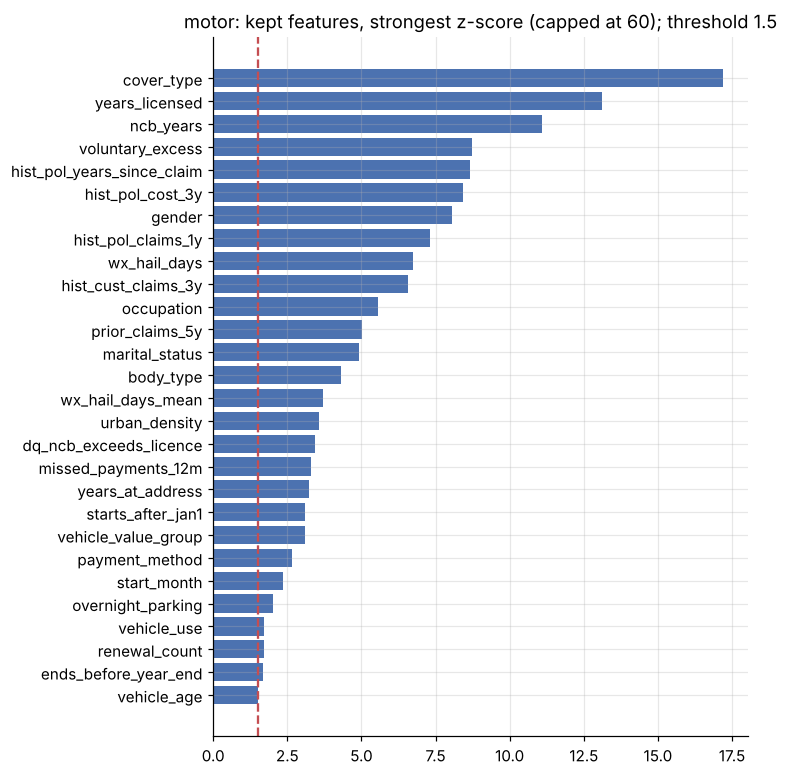

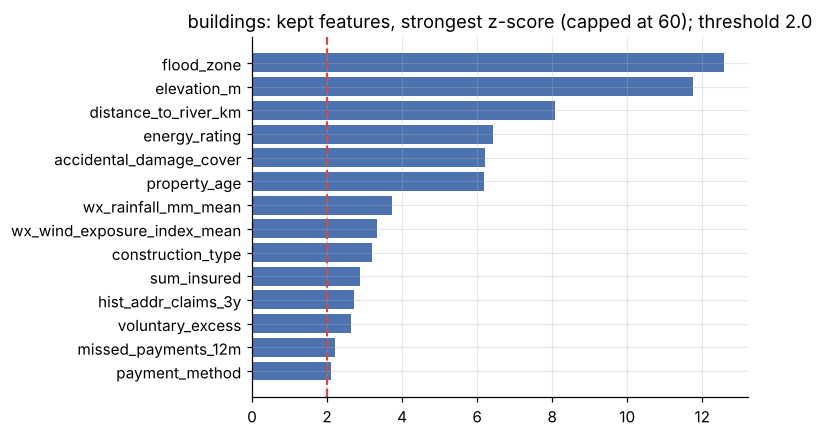

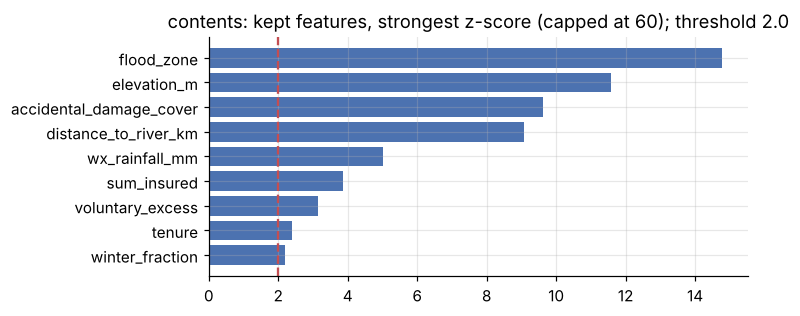

In [8]:
zc = [c for c in reg.columns if c.endswith("_z")]
for line in C.LINES:
    r = reg.loc[(reg["line"] == line) & (reg["decision"] == "keep") & (reg["reason"] == "adds value")].copy()
    r["best z"] = r[zc].max(axis=1)
    r = r.sort_values("best z")
    thr = float(reg.loc[reg["line"] == line, "z_threshold"].dropna().iloc[0])
    fig, ax = plt.subplots(figsize=(7, 0.22 * len(r) + 1))
    ax.barh(r["column"], r["best z"].clip(upper=60), color="#4C72B0")
    ax.axvline(thr, color="#C44E52", ls="--")
    ax.set_title(f"{line}: kept features, strongest z-score (capped at 60); threshold {thr}")
    plt.tight_layout(); plt.show()

Dropped columns and why:

In [9]:
reg.loc[reg["decision"] == "drop", ["line", "column", "reason", "evidence"]].sort_values(["line", "reason", "column"])

,line,column,reason,evidence
103,buildings,compulsory_excess,constant,one value on 100.00% of training rows (350)
180,buildings,hist_pol_escape_of_water_3y,constant,one value on 99.53% of training rows (0.0)
178,buildings,hist_pol_flood_3y,constant,one value on 99.84% of training rows (0.0)
179,buildings,hist_pol_subsidence_3y,constant,one value on 99.92% of training rows (0.0)
114,buildings,dq_exposure_fixed,data-quality flag,records a correction (kept in data/clean); no risk meaning
...,...,...,...,...
90,motor,hist_years_available,not testable,constant within every test year (a calendar-year proxy); the window length is known from renewal_count and hist_pol_...
32,motor,surname,personal data,"personal identifier, no risk meaning"
40,motor,customer_since_year,redundant,year - customer_since_year == renewal_count on 100.00% of rows
23,motor,new_business,redundant,new_business == (renewal_count == 0) on 100.00% of rows


Calibration on the random probes. Each line's z threshold is the lowest of 1.0 / 1.5 / 2.0 / 2.5 at which at most 1 of the 20 probes would pass a test against the other probes (a false-keep rate of about 5%): thin data get a stricter threshold because their z-scores are noisier.

In [10]:
reg.groupby("line")[["z_threshold", "probe_false_passes"]].first()

,z_threshold,probe_false_passes
line,,
buildings,2.0,1.0
contents,2.0,1.0
motor,1.5,0.0


Missing values: a flag is added only where missing rows claim differently from the rest.

In [11]:
pd.read_csv(C.REPORTS / "03_features" / "missing_values.csv")

,column,missing_pct,claims_missing,frequency_relativity,z,informative,note,line
0,vehicle_age,11.85,820.0,0.980,-0.5,False,NaN,motor
1,overnight_parking,12.05,854.0,1.000,0.0,False,NaN,motor
2,occupation,12.04,835.0,0.981,-0.5,False,NaN,motor
3,marital_status,12.08,831.0,0.971,-0.8,False,NaN,motor
4,years_at_address,11.89,802.0,0.949,-1.4,False,NaN,motor
5,hist_pol_years_since_claim,93.46,NaN,NaN,NaN,False,"missing exactly when hist_pol_claims_1y says so: structural, no flag needed",motor
6,flood_zone,2.82,43.0,1.466,2.5,False,NaN,buildings
7,distance_to_river_km,11.91,131.0,1.051,0.5,False,NaN,buildings
8,energy_rating,11.87,121.0,0.955,-0.5,False,NaN,buildings
9,flood_zone,2.86,34.0,1.204,1.1,False,NaN,contents


## 4. The outputs
One training and one 2025 table per line, named as in the case study. The 2025 tables have the same features and no targets.

In [12]:
ss = H.read_table("sample_submission", "clean")
out = []
ids = []
for line in C.LINES:
    for kind in ("policies", "test"):
        f = H.read_table(f"{kind}_{line}", "features")
        out.append({"file": f"data/features/{kind}_{line}.parquet", "rows": len(f), "columns": f.shape[1]})
        if kind == "test":
            ids.append(f["row_id"])
ids = pd.concat(ids)
print("2025 rows equal the sample submission:", set(ids) == set(ss["row_id"]), "| duplicates:", int(ids.duplicated().sum()))
leak = [c for c in reg.loc[reg["reason"] == "leakage", "column"].unique()]
print("leakage columns in any output:", [c for c in leak for line in C.LINES
                                         if c in H.read_table(f"policies_{line}", "features").columns])
pd.DataFrame(out)

2025 rows equal the sample submission: True | duplicates: 0
leakage columns in any output: []


,file,rows,columns
0,data/features/policies_motor.parquet,47283,56
1,data/features/test_motor.parquet,90521,36
2,data/features/policies_buildings.parquet,27447,45
3,data/features/test_buildings.parquet,52295,22
4,data/features/policies_contents.parquet,34566,34
5,data/features/test_contents.parquet,66247,17
